# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [ ]:
%pip install imbalanced-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import expit
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
from sklearn.utils.validation import check_array, check_is_fitted, validate_data
from sklearn.dummy import DummyClassifier
from sklearn import metrics

from imblearn.pipeline import make_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [ ]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def _validate_params(self):
        if self.gd_type not in ("full", "stochastic"):
            raise ValueError(
                "gd_type must be 'full' or 'stochastic'"
            )

        if (
            isinstance(self.max_iter, (bool, np.bool_))
            or not isinstance(self.max_iter, (int, np.integer))
            or self.max_iter <= 0
        ):
            raise ValueError("max_iter must be a positive integer")

        if (
            isinstance(self.batch_size, (bool, np.bool_))
            or not isinstance(self.batch_size, (int, np.integer))
            or self.batch_size <= 0
        ):
            raise ValueError("batch_size must be a positive integer")

        if not np.isscalar(self.eta) or not np.isfinite(self.eta):
            raise ValueError("eta must be a finite positive number")

        if self.eta <= 0:
            raise ValueError("eta must be positive")

        if (
            not np.isscalar(self.tolerance)
            or not np.isfinite(self.tolerance)
            or self.tolerance < 0
        ):
            raise ValueError(
                "tolerance must be a finite non-negative number"
            )

    def _add_bias(self, X):
        return np.column_stack((np.ones(X.shape[0]), X))


    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        self._validate_params()

        X, y = validate_data(
            self,
            X,
            y,
            dtype=np.float64,
            ensure_min_samples=1,
        )

        if not np.all(np.isin(y, [0, 1])):
            raise ValueError("y must contain only 0 and 1")

        if np.unique(y).size != 2:
            raise ValueError("Both classes 0 and 1 must be present")

        N, d = X.shape

        if self.gd_type == "stochastic":
            if self.batch_size > N:
                raise ValueError(
                    "batch_size cannot exceed the number of samples"
                )

        X = self._add_bias(X)
        self.classes_ = np.array([0, 1])

        if self.w0 is None:
            self.w = np.zeros(d + 1, dtype=float)
        else:
            self.w = np.array(self.w0, dtype=float, copy=True)

            if self.w.shape != (d + 1,):
                raise ValueError(
                    f"w0 must have shape ({d + 1},), "
                    f"got {self.w.shape}"
                )

            if not np.all(np.isfinite(self.w)):
                raise ValueError("w0 must contain only finite values")


        rng = np.random.default_rng(self.random_state)

        self.loss_history = []
        self.n_iter_ = 0

        for i in range(self.max_iter):
            loss = self.calc_loss(X, y)

            if not np.isfinite(loss):
                raise FloatingPointError(
                    "Non-finite loss encountered"
                )

            self.loss_history.append(loss)

            if self.gd_type == "full":
                X_batch, y_batch = X, y
            else:
                indices = rng.choice(
                    N,
                    size=self.batch_size,
                    replace=False,
                )
                X_batch = X[indices]
                y_batch = y[indices]

            grad = self.calc_gradient(X_batch, y_batch)

            if not np.all(np.isfinite(grad)):
                raise FloatingPointError(
                    "Non-finite gradient encountered"
                )

            self.w -= self.eta * grad
            self.n_iter_ += 1

            if not np.all(np.isfinite(self.w)):
                raise FloatingPointError(
                    "Non-finite weights encountered"
                )

            if np.linalg.norm(self.eta * grad) < self.tolerance:
                break

        return self

    def sigmoid(self, z):
        return expit(z)

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = self._add_bias(X)
        p = self.sigmoid(X @ self.w.T)

        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        if (
            not np.isscalar(threshold)
            or not np.isfinite(threshold)
            or not 0 <= threshold <= 1
        ):
            raise ValueError("threshold must be between 0 and 1")

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        y_signed = 2 * y - 1
        margins = y_signed * (X @ self.w)
        return X.T @ (-y_signed * self.sigmoid(-margins)) / X.shape[0]


    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        y_signed = 2 * y - 1
        margins = y_signed * (X @ self.w)
        return float(np.mean(np.logaddexp(0, -margins)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [ ]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.17e-10


Теперь проверим работу класса на синтетических данных.

In [ ]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

Full GD: 1000 итераций
SGD:     1000 итераций


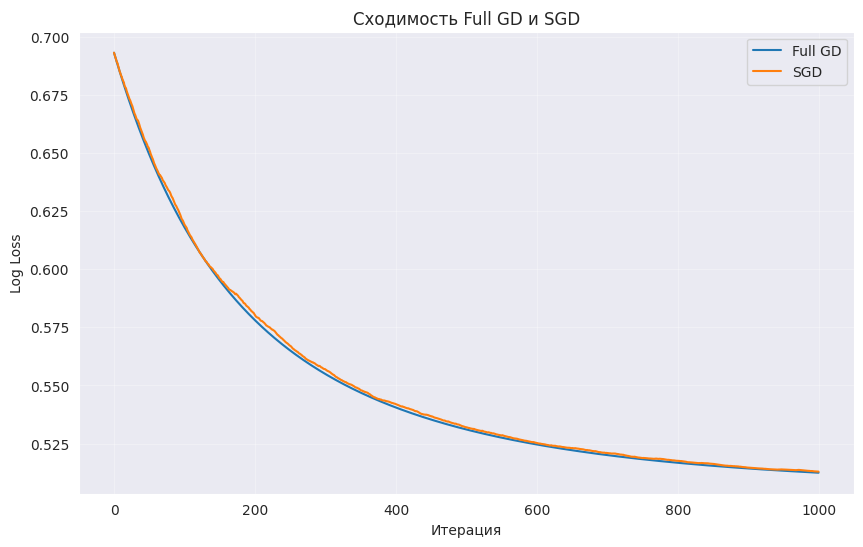

In [ ]:
model_full = LogReg(gd_type='full')
model_sgd = LogReg(gd_type='stochastic', random_state=RANDOM_STATE)

model_full.fit(X_train, y_train)
model_sgd.fit(X_train, y_train)

print(f"Full GD: {model_full.n_iter_} итераций")
print(f"SGD:     {model_sgd.n_iter_} итераций")

plt.figure(figsize=(10, 6))

plt.plot(model_full.loss_history, label='Full GD')
plt.plot(model_sgd.loss_history, label='SGD')

plt.xlabel('Итерация')
plt.ylabel('Log Loss')
plt.title('Сходимость Full GD и SGD')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

*Ваши выводы здесь.*
- Каждая модель остановилась по критерию `max_iter`, совершив ровно 1000 итераций оптимизации.
- Я бы не сказал, что стохастическому градиентному спуску именно трудно остановиться по критерию `tolerance`. Вернее будет сказать, что для SGD критерий в том виде, в каком он реализован, не совсем корректный. По сути мы смотрим на градиент модели в данной точке умноженный на шаг `eta`. Для SGD малое значение нормы этого вектора вовсе не означает, что мы в локальном минимуме для функции, вычисленной на всей выборке. Причина в том, что градиент для SGD шумный, особенно вблизи локального минимума. Собственно это и есть объяснение того, почему стахстическому градиентному спуску действительно может быть трудно остановиться по критерию `tolerance`. Более того тут есть ещё один момент, который нужно иметь ввиду: шаг `eta` буквально влияет на возможность остановки по этому критерию. То есть, если выбрать слишком маленькое `eta`, то мы можем остановиться слишком рано. В общем для SGD это весьма проблемный критерий.
- В целом графики функции потерь почти идентичны, разве что GD гладкий, а SGD пошумнее. Причина гладкости в выпуклости используемой функции потерь (логистическая). Причина шумности в устройстве SGD. Качество почти не отличается, поэтому использование SGD будет предпочтительнее.
- GD просматривает всю выборку, то есть 20000 объектов за итерацию. SGD просматривает 32 объекта, то есть в 625 раз больше. При том, что разница околонулевая, логично использовать именно SGD для данной модели.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

eta = 0.001  | Final loss = 0.618141 | Iterations = 1000
eta = 0.01   | Final loss = 0.512451 | Iterations = 1000
eta = 0.1    | Final loss = 0.505762 | Iterations = 465
eta = 1      | Final loss = 0.505757 | Iterations = 70
eta = 10     | Final loss = 0.945807 | Iterations = 1000


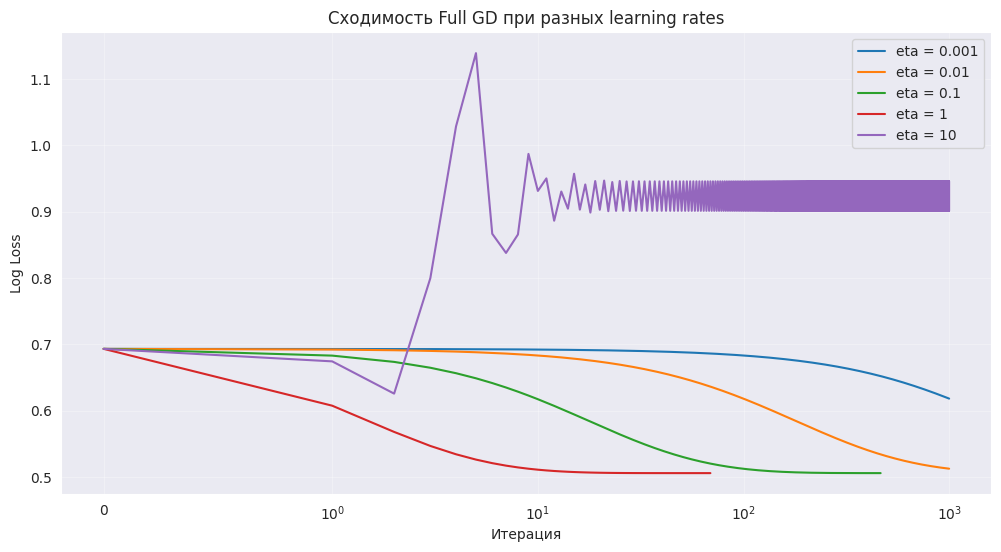

In [ ]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
models = {}

plt.figure(figsize=(12, 6))

for eta in etas:
    model = LogReg(gd_type='full', eta=eta, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    models[eta] = model

    print(
        f"eta = {eta:<6g} | "
        f"Final loss = {model.loss_history[-1]:.6f} | "
        f"Iterations = {model.n_iter_}"
    )

    plt.plot(
        range(len(model.loss_history)),
        model.loss_history,
        label=f'eta = {eta:g}'
    )

plt.xscale('symlog', linthresh=1)
plt.xlabel('Итерация')
plt.ylabel('Log Loss')
plt.title('Сходимость Full GD при разных learning rates')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

*Ваши выводы здесь.*

Интересно смотреть на логарифмический масштаб для итераций, но это отражает
важную мысль: с оптимальным шагом модель сходится на порядок итераций быстрее. Итак, с наибольшим шагом `eta=10` модель расходится. С шагом поменьше, но всё ещё относительном большим, `eta=1` модель почти сходится где-то за 10 итераций и останавливается по критерию `tolerance` на 70 итерации. Весьма быстро надо сказать. С `eta=0.1` модель также останавливается по критерию `tolarance`, но только на 465 итерации. С `eta=0.01` и `eta=0.001` модель не успевает сойтись за 1000 итераций. Вывод следующий: при оптимизации моделей с выпуклой функцией потерь подбор оптимального шага может значительно повлиять на скорость сходимости. Почему я упомянул выпуклость? Потому что для выпуклой функции потерь любой локальный минимум является глобальным, поэтому при корректном выборе шага градиентный спуск может сходиться к глобальному минимуму. В случае невыпуклой функции ситуация сложнее: алгоритм может застрять в локальном минимуме или седловой точке, а результат зависит в том числе от начальной инициализации. Таким образом, для выпуклых задач подбор шага позволяет сосредоточиться прежде всего на скорости и устойчивости сходимости, а не на поиске подходящего локального минимума.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [ ]:
model_full = LogReg(gd_type='full').fit(X_train, y_train)
model_sgd = LogReg(gd_type='stochastic', random_state=RANDOM_STATE).fit(X_train, y_train)

model_sklearn = LogisticRegression(random_state=RANDOM_STATE)
model_sklearn.fit(X_train, y_train)

models = {
    'Full GD': model_full,
    'SGD': model_sgd,
    'sklearn': model_sklearn
}


results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Log Loss': log_loss(y_test, y_proba)
    })

results_df = pd.DataFrame(results).set_index('Model')
display(results_df)


weights_df = pd.DataFrame({
    'Full GD': model_full.w,
    'sklearn': np.r_[
        model_sklearn.intercept_,
        model_sklearn.coef_.ravel()
    ]
}, index=['intercept'] + [f'w{i}' for i in range(X_train.shape[1])])

weights_df['Absolute difference'] = (
    weights_df['Full GD'] - weights_df['sklearn']
).abs()

display(weights_df)

print(
    'L2 distance between weights:',
    np.linalg.norm(
        weights_df['Full GD'] - weights_df['sklearn']
    )
)

,Accuracy,ROC-AUC,Log Loss
Model,,,
Full GD,0.7820,0.838787,0.510324
SGD,0.7825,0.838115,0.511014
sklearn,0.7765,0.838676,0.504232


,Full GD,sklearn,Absolute difference
intercept,-0.002114,-0.021880,0.019765
w0,0.006076,0.002741,0.003335
w1,0.006963,0.009039,0.002077
w2,-0.547170,-0.722690,0.175520
w3,-0.144536,-0.262335,0.117799
w4,0.012487,0.016588,0.004102
w5,-0.006325,-0.011488,0.005163
w6,0.000814,0.005587,0.004773
w7,0.039084,0.057188,0.018104
w8,-0.002425,-0.001239,0.001185


L2 distance between weights: 0.35678325060907723


*Ваши выводы здесь.*

Я добавил вывод логистической функции потерь, чтобы было ясно, что модель sklearn получает меньший loss, хотя accuracy у нашей модели чуть лучше. В общем метрики различаются, как и веса. Для некоторых признаков они весьма похожи, но в целом есть значительная разница. Причина этого в том, что модель sklearn по дефолту использует регуляризацию, а в нашей модели её нет. Это и приводит к разнице в метриках и весах. Давайте это исправим.

In [ ]:
model_full = LogReg(
    gd_type='full',
    eta=0.1,
    max_iter=20000,
    tolerance=1e-8
).fit(X_train, y_train)

model_sgd = LogReg(
    gd_type='stochastic',
    eta=0.1,
    max_iter=20000,
    tolerance=1e-8,
    random_state=RANDOM_STATE
).fit(X_train, y_train)

model_sklearn = LogisticRegression(
    penalty=None,
    tol=1e-10,
    max_iter=10000,
    random_state=RANDOM_STATE
).fit(X_train, y_train)

models = {
    'Full GD (converged)': model_full,
    'SGD (converged)': model_sgd,
    'sklearn (no reg)': model_sklearn
}


results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Log Loss': log_loss(y_test, y_proba)
    })

results_df = pd.DataFrame(results).set_index('Model')
display(results_df)


weights_df = pd.DataFrame({
    'Full GD': model_full.w,
    'sklearn': np.r_[
        model_sklearn.intercept_,
        model_sklearn.coef_.ravel()
    ]
}, index=['intercept'] + [f'w{i}' for i in range(X_train.shape[1])])

weights_df['Absolute difference'] = (
    weights_df['Full GD'] - weights_df['sklearn']
).abs()

display(weights_df)

print(
    'L2 distance between weights:',
    np.linalg.norm(
        weights_df['Full GD'] - weights_df['sklearn']
    )
)

print(f"Full GD iterations: {model_full.n_iter_}")
print(f"SGD iterations:     {model_sgd.n_iter_}")
print(f"sklearn iterations: {model_sklearn.n_iter_[0]}")

,Accuracy,ROC-AUC,Log Loss
Model,,,
Full GD (converged),0.776500,0.838673,0.504233
SGD (converged),0.783167,0.838894,0.505727
sklearn (no reg),0.776500,0.838673,0.504233


,Full GD,sklearn,Absolute difference
intercept,-0.022163,-0.022163,1.558478e-07
w0,0.002762,0.002762,8.747416e-09
w1,0.008962,0.008962,5.805746e-09
w2,-0.723248,-0.723248,4.769013e-07
w3,-0.262775,-0.262776,4.158663e-07
w4,0.016537,0.016537,5.937545e-10
w5,-0.011549,-0.011549,1.267335e-08
w6,0.005580,0.005580,2.847717e-08
w7,0.057240,0.057240,5.475937e-08
w8,-0.001201,-0.001201,5.425063e-09


L2 distance between weights: 1.090589366932669e-06
Full GD iterations: 1480
SGD iterations:     20000
sklearn iterations: 11


Убрав регуляризацию из модели sklearn и добавив большое число итераций в наши модели, мы получили идентичные результаты для Full GD и sklearn как в метриках, так и в весах, но немного отличающиеся для SGD. Сначала отмечу, что sklearn сошёлся за 11 итераций. По дефолту там используется `lbfgs`, поэтому такая быстрая сходимость. Full GD сошёлся за 1480 итераций, что много, но учитывая предыдущий опыт с подбором шага, вполне возможно, что можно получить такой результат быстрее. Интересно здесь также отметить, что SGD за 20000 итераций так и не получил идентичный loss. Причина наверняка в шумности градиента около локального минимума, которая и не позволяла попасть в глобальный минимум. Это можно решить, если использовать убывающий шаг в оптимизации. При всём этом accuracy у SGD вышло больше. В принципе это может служить примером того, как шумность градиента SGD выступает в роли неявной регуляризации.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [ ]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [ ]:
# Пропуски
missing = df.isna().sum()

# Полные дубликаты
n_duplicates = df.duplicated().sum()

# Дубликаты между train и test (включая target)
train_full = X_train.assign(target=y_train)
test_full = X_test.assign(target=y_test)

train_rows = pd.MultiIndex.from_frame(train_full.reset_index(drop=True))
test_rows = pd.MultiIndex.from_frame(test_full.reset_index(drop=True))

cross_duplicates = test_rows.isin(train_rows)
n_cross_duplicates = cross_duplicates.sum()

# Доли положительного класса
train_prevalence = y_train.mean()
test_prevalence = y_test.mean()

data_summary = pd.DataFrame({
    'Metric': [
        'Total samples',
        'Features',
        'Missing values',
        'Full duplicates',
        'Train-test duplicates',
        'Train prevalence',
        'Test prevalence'
    ],
    'Value': [
        len(df),
        X.shape[1],
        missing.sum(),
        n_duplicates,
        n_cross_duplicates,
        f'{train_prevalence:.2%}',
        f'{test_prevalence:.2%}'
    ]
})

display(data_summary.style.hide(axis='index'))

display(
    missing.to_frame('Missing values')
    .style
    .background_gradient(cmap='Blues')
)

Metric,Value
Total samples,6497
Features,12
Missing values,0
Full duplicates,1177
Train-test duplicates,537
Train prevalence,19.66%
Test prevalence,19.64%


,Missing values
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


Пропусков совсем нет, поэтому о них думать не нужно. При этом дубликатов очень много. Возникает вопрос, что с ними делать? Понятное дело, что нужно удалить дубликаты из пересечения train и test, чтобы не было data leakage. При этом дубликаты вполне могут остаться внутри train и test. Давайте это сделаем и продолжим мысль.

In [ ]:
# Независимая тестовая выборка без пересечений с train
X_test_clean = X_test.loc[~cross_duplicates].copy()
y_test_clean = y_test.loc[~cross_duplicates].copy()

split_summary = pd.DataFrame({
    'Dataset': ['Train', 'Test (original)', 'Test (clean)'],
    'Samples': [len(X_train), len(X_test), len(X_test_clean)],
    'Prevalence': [
        y_train.mean(),
        y_test.mean(),
        y_test_clean.mean()
    ]
})

display(
    split_summary.style
    .hide(axis='index')
    .format({'Prevalence': '{:.2%}'})
)

Dataset,Samples,Prevalence
Train,4547,19.66%
Test (original),1950,19.64%
Test (clean),1413,18.68%


При удаление дубликатов из test распределение целевой перменной немного меняется. Вообще критичность этого зависит от требований и условий задачи. Мы можем намеренно допустить другое распределение test, чтобы проверять работу модели в отличающихся от train условиях. Если же мы этого заранее не предполагаем, то могут возникнуть проблемы с оценкой качества и получением хорошей модели, так как в действительности мы будем учить модель на одном, а проверять на другом. Чтобы этого избежать нужно удалить дубликаты, а потом разбить выборку на train и test. Другой момент, что тогда мы удалим все дубли, но непонятно нужно ли нам это. Так как в датасете нет каких-то текстовых названий вин, то сложно сказать, что это за дубли: одинаковые объекты или разные объекты с одинаковыми описаниями. Я предпочитаю максимально честные оценки экспериментов, поэтому удалю все дубли из датасета и проведу разбиение ещё раз.

In [ ]:
df = pd.read_csv(
    'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv'
)

# Проверка дубликатов
n_samples = len(df)
n_duplicates = df.duplicated().sum()

# Одинаковые признаки с разными target
feature_cols = df.columns.drop('target')

conflicting_groups = (
    df.groupby(list(feature_cols), dropna=False)['target']
    .nunique()
)

n_conflicting_groups = (conflicting_groups > 1).sum()

# Удаление полных дубликатов
df_clean = df.drop_duplicates().reset_index(drop=True)

# Признаки и целевая переменная
X = df_clean.drop(columns='target')
y = df_clean['target']

# Стратифицированное разбиение
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y
)

# Проверка пересечений по признакам
train_features = pd.MultiIndex.from_frame(
    X_train.reset_index(drop=True)
)
test_features = pd.MultiIndex.from_frame(
    X_test.reset_index(drop=True)
)

n_overlap = test_features.isin(train_features).sum()

# Сводная таблица
summary = pd.DataFrame({
    'Dataset': ['Original', 'Clean', 'Train', 'Test'],
    'Samples': [
        len(df),
        len(df_clean),
        len(X_train),
        len(X_test)
    ],
    'Prevalence': [
        df['target'].mean(),
        y.mean(),
        y_train.mean(),
        y_test.mean()
    ]
})

display(
    summary.style
    .hide(axis='index')
    .format({'Prevalence': '{:.2%}'})
)

print(f'Full duplicates removed: {n_duplicates} ({n_duplicates / n_samples:.2%})')
print(f'Conflicting feature groups: {n_conflicting_groups}')
print(f'Train-test feature overlap: {n_overlap}')

Dataset,Samples,Prevalence
Original,6497,19.66%
Clean,5320,18.97%
Train,3724,18.96%
Test,1596,18.98%


Full duplicates removed: 1177 (18.12%)
Conflicting feature groups: 0
Train-test feature overlap: 0


Да, датасет стал заметно меньше, что, конечно, не очень хорошо и можно бить по рукам за такое, но теперь нет никаких дублей и распределение целевой переменной на train и test одинаковое. Это всё же учебный пример, поэтому больших проблем с уменьшением данных не должно быть. Отмечу, что кроме полных дубликатов (т.е. с целевой переменной) сделана проверка дубликатов по признакам, т.к. могут быть объекты с одинаковыми характеристиками, но разными оценками качества. По итогу таких объектов нет, что означает также отсутсвие дублей по признаковым описаниям.

In [ ]:
# Константная модель
model_dummy = DummyClassifier(strategy='constant', constant=0)
model_dummy.fit(X_train, y_train)

# Логистическая регрессия
model_logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
model_logreg.fit(X_train, y_train)

# Предсказания
y_pred_dummy = model_dummy.predict(X_test_clean)
y_pred_logreg = model_logreg.predict(X_test_clean)

# Accuracy
accuracy_dummy = accuracy_score(y_test_clean, y_pred_dummy)
accuracy_logreg = accuracy_score(y_test_clean, y_pred_logreg)

# Сохранение результатов
results_dummy = {
    'Model': 'Dummy (constant 0)',
    'Accuracy': accuracy_dummy
}

results_logreg = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_logreg
}

# Сравнение моделей
results = pd.DataFrame([
    results_dummy,
    results_logreg
])

display(
    results.style
    .hide(axis='index')
    .format({'Accuracy': '{:.4f}'})
    .background_gradient(subset=['Accuracy'], cmap='Blues')
)

Model,Accuracy
Dummy (constant 0),0.8132
Logistic Regression,0.8266


Конечно, кроме accuracy можно было посчитать что-нибудь ещё, но это следующее задания, поэтому обсудить только это. Итак, есть две модели. Первая всегда говорит, что вино "не хорошее". Таким образом модель отвергает любой предлагаемый вариант. Вторая модель вроде что-то выучивает из данных, но получает accuracy на уровне первой модели. В чём же дело? Нужно вспомнить про распределение целевой переменной, а именно, что доля положительного классов около 19%. Это объясняет, почему первая модель получает такой хороший результат и даёт понять, что по accuracy совершенно непонятно качество второй модели. Это подводит нас к тому, что нужно смотреть и на другие метрики. В данном случае из-за дисбаланса классов accuracy не подходит. Тем более, если вспомнить условие, в котором говорится что "Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной)".

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP = 92, TN = 1209, FP = 84, FN = 211
Matrices match: True


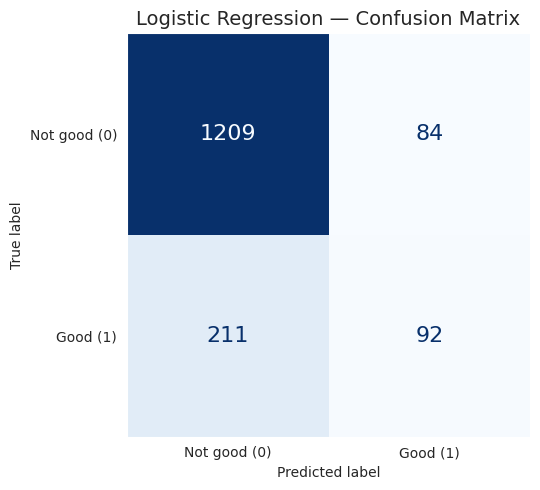

In [ ]:
# Предсказания логистической регрессии
y_pred = model_logreg.predict(X_test)

# Ручной расчёт элементов матрицы ошибок
TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

# Сравнение с sklearn
cm_manual = np.array([
    [TN, FP],
    [FN, TP]
])

cm_sklearn = metrics.confusion_matrix(y_test, y_pred)

print(f'TP = {TP}, TN = {TN}, FP = {FP}, FN = {FN}')
print(f'Matrices match: {np.array_equal(cm_manual, cm_sklearn)}')

# Визуализация
fig, ax = plt.subplots(figsize=(6, 5))

disp = metrics.ConfusionMatrixDisplay(
    confusion_matrix=cm_sklearn,
    display_labels=['Not good (0)', 'Good (1)']
)

disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)

ax.grid(False)

for text in disp.text_.ravel():
    text.set_fontsize(16)

ax.set_title('Logistic Regression — Confusion Matrix', fontsize=14)
plt.tight_layout()
plt.show()

В test 1596 объектов, из которых 303 относятся к положительному классу. Логичестическая регрессия правильно относит к отрицательному классу 1209/1293 объектов и к положительному 92/303. Нетрудно увидеть, что значение False Negative, которое равно 211, выделяется сильнее всего. Оно включает объекты, которые модель классифицировала как "не хорошие" вина, но на самом деле они хорошие. То есть это величина напрямую связана с тем, что модель пропускает хорошие вина. False Positive же меньше на фоне всего отрицательного класса и составляет 84 ошибки. Это вина, которая модель назвала хорошими, но он "не хорошие" на самом деле. Так как True Positive всего 92, то уже на этом фоне FP выглядит весьма большим, т.к. когда модель говорит, что вино хорошее часто это не так. Это напрямую связано с тем мы не хотим рекомендовать клиенту посредственное вино. Итого даже без метрик классификации по этой табличке видно, что логистическая регрессия имеет значительные проблемы в предсказание качества вина с практической точки зрения.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [ ]:
# Ручной расчёт метрик
precision = TP / (TP + FP)
recall = TP / (TP + FN)

def fbeta(precision, recall, beta):
    beta2 = beta ** 2
    return (1 + beta2) * precision * recall / (beta2 * precision + recall)

f1 = fbeta(precision, recall, beta=1)
f05 = fbeta(precision, recall, beta=0.5)
f2 = fbeta(precision, recall, beta=2)

# Проверка через sklearn
metrics_manual = {
    'Precision': precision,
    'Recall': recall,
    'F1': f1,
    'F0.5': f05,
    'F2': f2
}

metrics_sklearn = {
    'Precision': metrics.precision_score(y_test, y_pred),
    'Recall': metrics.recall_score(y_test, y_pred),
    'F1': metrics.fbeta_score(y_test, y_pred, beta=1),
    'F0.5': metrics.fbeta_score(y_test, y_pred, beta=0.5),
    'F2': metrics.fbeta_score(y_test, y_pred, beta=2)
}

# Сравнение результатов
comparison = pd.DataFrame({
    'Manual': metrics_manual,
    'sklearn': metrics_sklearn
})

comparison['Difference'] = abs(comparison['Manual'] - comparison['sklearn'])

display(
    comparison.style
    .format('{:.6f}')
    .background_gradient(subset=['Manual'], cmap='Blues')
)

,Manual,sklearn,Difference
Precision,0.522727,0.522727,0.000000
Recall,0.303630,0.303630,0.000000
F1,0.384134,0.384134,0.000000
F0.5,0.456802,0.456802,0.000000
F2,0.331412,0.331412,0.000000


Для начала отметим, что значения этих метрик качества классификации сильно меньше, чем ранее расммотренный accuracy. Здесь сразу видно, что качество сомнительное, особенно если смотреть на $F$-меру, которая совмещает значения точности и полноты. Точность или precision — доля действительно положительных объектов среди всех, которые модель назвала положительными. Полнота или recall показывает долю истинно положительных объектов, которую покрывает модель. Стандартная $F_1$-мера в равной мере учитывает precision и recall. $F_{\beta}$-мера позволяет изменить вклад этих величин. При $\beta < 1$ больше ценится precision (в граничном случае, когда $\beta = 0$, $F_0$ это precision). При $\beta > 1$ больший вклад у recall (в граничном случае, когда $\beta \to \infty$, $F_\infty$ это recall). Таким образом $F_{0.5}$ ближе к значению precision, а $F_2$ ближе к значению recall. Цифры это подтверждают. Интересно, что в данном случае $F_{0.5}$-мера очень близка к precision, а $F_2$-мера очень близка к recall. Можно подумать, что тогда такая $F_\beta$-мера не нужна, но она всё ещё полезна, так как позволяет агрегировать два значения в одно и избежать ситуации, когда из-за увеличения одной метрики, другая сильно пострадала. В целом, конечно, хорошо иметь перед глазами все чиселки, чтобы ничего не упустить.

Когда появляется $F_\beta$-мера, то возникает вопрос, какую именно использовать? Нормальная практика использовать $F_1$-меру когда в равной степени важны precision и recall, $F_{0.5}$, когда важнее precision, и $F_2$, когда важнее recall. Более специфические значения $\beta$ должны быть как-то обоснованы, потому что не очень понятно, почему другие значения могут быть предпочтительнее. В нашей задаче, если важно, что подписчики очень болезненно реагируют на посредственные вина в подборке, то нужен высокий precision, а значит лучше использовать $F_{0.5}$-меру. Если сервис позиционирует себя как «самая широкая подборка хороших вин», то стараться делать побольше recall и использовать $F_2$-меру.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

In [ ]:
model_logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)
model_logreg.fit(X_train, y_train)

model_custom = make_pipeline(
    StandardScaler(),
    LogReg(
        gd_type='full',
        eta=5,
        max_iter=20000,
        tolerance=1e-8,
        random_state=RANDOM_STATE
    )
)
model_custom.fit(X_train, y_train)

# Непрерывные оценки (вероятность класса 1)
p_sklearn = model_logreg.predict_proba(X_test)[:, 1]
p_custom = model_custom.predict_proba(X_test)[:, 1]

# Проверка сходимости
custom_logreg = model_custom.named_steps['logreg']

print(f'Iterations: {custom_logreg.n_iter_}')
print(f'Initial loss: {custom_logreg.loss_history[0]:.6f}')
print(f'Final loss: {custom_logreg.loss_history[-1]:.6f}')
print(f'Max probability difference: {np.max(np.abs(p_sklearn - p_custom)):.6f}')

Iterations: 1334
Initial loss: 0.693147
Final loss: 0.365807
Max probability difference: 0.020094


Перебрал ручками `eta`, получив такой финальный loss. Стоит ещё раз отметить, что так как стандартная логистическая регрессия из sklearn использует регулярзацию, поэтому будут отличия.

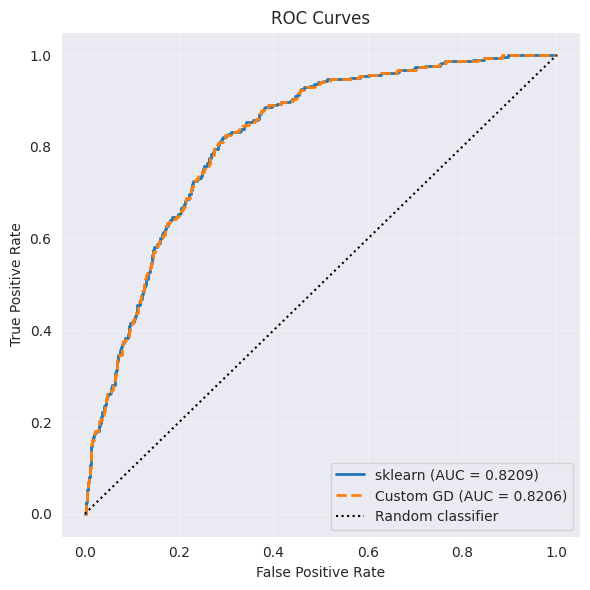

In [ ]:
# ROC-кривые
fpr_sklearn, tpr_sklearn, _ = metrics.roc_curve(y_test, p_sklearn)
fpr_custom, tpr_custom, _ = metrics.roc_curve(y_test, p_custom)

# ROC-AUC
roc_auc_sklearn = metrics.roc_auc_score(y_test, p_sklearn)
roc_auc_custom = metrics.roc_auc_score(y_test, p_custom)

# Визуализация
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(
    fpr_sklearn, tpr_sklearn,
    label=f'sklearn (AUC = {roc_auc_sklearn:.4f})',
    linewidth=2
)

ax.plot(
    fpr_custom, tpr_custom,
    label=f'Custom GD (AUC = {roc_auc_custom:.4f})',
    linewidth=2,
    linestyle='--'
)

ax.plot([0, 1], [0, 1], 'k:', label='Random classifier')

ax.set(
    xlabel='False Positive Rate',
    ylabel='True Positive Rate',
    title='ROC Curves'
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Во-первых, разница между нашей моделью и моделью sklearn отсутствует. И это проявляется не только в значение AUC, но и в форме графика. Возможно, если подобрать оптимальное значение коэффициента регуляризации, то можно получить более качественное изменение. Во-вторых, значение AUC и форма графика ещё раз указывает нам, что модели что-то выучивают из данных и решают задачу разумнее, чем случайный классификатор. При этом стоит отметить, что значение AUC для "разумных" моделей начинается от 0.5. Чтобы исправить это, можно использовать индекс Джини ($2AUC - 1$), который в данно случае равен `0.64`. Нормальный результат, но есть к чему стремится. В-третьих, само значение ROC-AUC означает, что с вероятностью около 82% случайно выбранный положительный объект получит более высокую оценку, чем случайно выбранный отрицательный. При это доля положительного классо около 19%, поэтому ROC-кривая не полностью отражает практическую эффективность классификации, т.к. при относительном небольшом FPR количество ложноположительных (FP) предсказаний может быть значительным. Чтобы это учесть нужно посмотреть на PR-кривую.

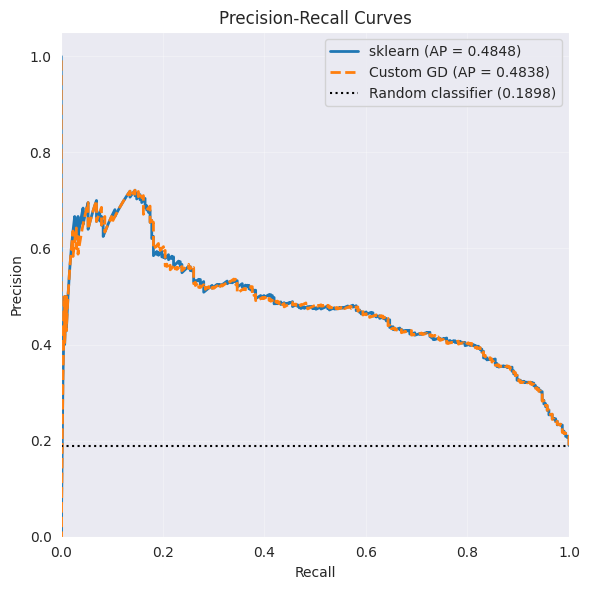

In [ ]:
# PR-кривые
precision_sklearn, recall_sklearn, _ = metrics.precision_recall_curve(
    y_test, p_sklearn
)
precision_custom, recall_custom, _ = metrics.precision_recall_curve(
    y_test, p_custom
)

# Average Precision
pr_auc_sklearn = metrics.average_precision_score(y_test, p_sklearn)
pr_auc_custom = metrics.average_precision_score(y_test, p_custom)

# Уровень случайной модели
prevalence = y_test.mean()

# Визуализация
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(
    recall_sklearn, precision_sklearn,
    label=f'sklearn (AP = {pr_auc_sklearn:.4f})',
    linewidth=2
)

ax.plot(
    recall_custom, precision_custom,
    label=f'Custom GD (AP = {pr_auc_custom:.4f})',
    linewidth=2,
    linestyle='--'
)

ax.axhline(
    prevalence,
    color='black',
    linestyle=':',
    label=f'Random classifier ({prevalence:.4f})'
)

ax.set(
    xlabel='Recall',
    ylabel='Precision',
    title='Precision-Recall Curves',
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Разница между моделями также отсутствует, но разница при сравнение со случайным классификатором для PR-кривой ощущается меньшей, чем для ROC-кривой. Иначе говоря, смотря на PR-кривую, обученные модели видятся менее качественными по сравнению с оценкой качество по ROC-кривой. Модели плохо выделяет положительный класс. Если смотреть детальнее, то можно выделить следующее. При небольшом recall около `0.18` модель работает хорошо и имеет precision около `0.7`. Это достойно, если мы хотим рекомендовать именно хорошие вина. При увеличиении recall до `0.6` precision падает ниже `0.5`, вероятно, достигая баланса между двумя метриками и получая наибольшую $F_1$-меру. При большом recall качество значительно падает: модель обнарживает почти все положительные объекты, но при этом падает точность, то есть появляется большое число ложноположительных результатов.

In [ ]:
results = pd.DataFrame({
    'Model': ['sklearn', 'Custom GD'],
    'ROC-AUC': [roc_auc_sklearn, roc_auc_custom],
    'PR-AUC (AP)': [pr_auc_sklearn, pr_auc_custom]
})

display(
    results.style
    .hide(axis='index')
    .format({
        'ROC-AUC': '{:.4f}',
        'PR-AUC (AP)': '{:.4f}'
    })
    .background_gradient(
        subset=['ROC-AUC', 'PR-AUC (AP)'],
        cmap='Blues'
    )
)

Model,ROC-AUC,PR-AUC (AP)
sklearn,0.8209,0.4848
Custom GD,0.8206,0.4838


Табличка ни даёт ничего нового. Всё важное я уже отметил выше.

In [ ]:
eps = np.finfo(float).eps
p_clipped = np.clip(p_sklearn, eps, 1 - eps)

scores = {
    'p': p_sklearn,
    '10 * p': 10 * p_sklearn,
    'p^3': p_sklearn ** 3,
    'log(p / (1 - p))': np.log(p_clipped / (1 - p_clipped)),
    '-p': -p_sklearn
}

auc_original = metrics.roc_auc_score(y_test, p_sklearn)

transformation_results = pd.DataFrame([
    {
        'Transformation': name,
        'ROC-AUC': metrics.roc_auc_score(y_test, score)
    }
    for name, score in scores.items()
])

transformation_results['Difference'] = (
    transformation_results['ROC-AUC'] - auc_original
)

display(
    transformation_results.style
    .hide(axis='index')
    .format({
        'ROC-AUC': '{:.6f}',
        'Difference': '{:+.6f}'
    })
    .background_gradient(subset=['ROC-AUC'], cmap='Blues')
)

Transformation,ROC-AUC,Difference
p,0.820876,+0.000000
10 * p,0.820876,+0.000000
p^3,0.820876,+0.000000
log(p / (1 - p)),0.820876,+0.000000
-p,0.179124,-0.641752


При некоторых преобразованиях мы получили что-то, что уже никак не является вероятностью, но суть то не в этом. ROC-AUC не изменился для всех преобразований (в том числе и для последнего, дальше объясню, что я имею ввиду). Все использованные преобразования монотонны, поэтому они сохраняют ранжирование или меняют его на противоположное, как $-p$. ROC-AUC зависит именно от порядка объектов, а не от вычисленных значений для них, поэтому у $p$, $10p$, $p^3$, $\log \frac{p}{1 - p}$ ROC-AUC одинаковый, а у $-p$ он принял значений $1 - $ ROC-AUC, т.е. существенно не изменился, потому что можно вернуться к исходному значению, если изменить ранжирование на противоположное. Таким образом, этот пример показывает, что AUC-кривая оценивает качество ранжирование, и что применение мотонных преобразований выходов не даст никаких качественных улучшений модели.

*Ваши выводы здесь.*
- Я уже отмечал, что разницы в качестве у моделей нет, а оценки по ROC-AUC и PR-AUC значительно различаются.
- Я не объяснял почему ROC и PR кривые для случайной модели так выглядят, поэтому сейчас обосную. В целом случайный классификатор выдаёт положительный класс с вероятностью $p$. ROC-кривая строится в координатах:
$$
TPR=\frac{TP}{TP+FN},\qquad FPR=\frac{FP}{FP+TN}.
$$
Это означает, что среди всех положительных объектов доля предсказанных положительными равна $p$, следовательно, $TPR=p$. Среди всех отрицательных объектов доля предсказанных положительными тоже равна $p$, следовательно, $FPR = p$. Таким образом, $TPR=FPR=p$. Изменяя порог, то есть вероятность $p$ мы получаем всегда $TPR=FPR$, что и означает диагональную прямую. Для PR-кривой случайный классификатор аналогично выдаёт положительный класс с вероятностью $p$, который зависит от выбранного порога. Таким образом при увеличиние порога модель называет всё больше объектов положительными, увеличивая recall. При этом доля истинно положительных среди все объектов, которые модель назвала положительными, просто равна доле положительных объектов в датасете, т.к. модель присваивает метку независимо для каждого объекта. Это означает, что precision в данном случае всегда равен примерно 19%.
- Если подать в `roc_auc_score` предсказанные метки классов, то есть $0$ или $1$, мы получим очень странное ранжирование, где куча объектов слипнуться в один при варьирование порога. Для такой AUC-кривой будут три точки: $(0, 1)$ и $(1, 1)$, а также ещё одна $(FPR, TPR)$ данных меток. Площадь под такой кривой равна:
$$
ROC\text{-}AUC = \frac{TPR + 1 - FPR}{2}
$$
Наверное, это можно использовать, но тут полностью теряется интерпретация AUC-ROC, которая прежде всего измеряет качество ранжирования объектов моделью.


### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

In [ ]:
# Разбиение train на train и validation
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=RANDOM_STATE
)

# Обучение на subtrain
model_val = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)

model_val.fit(X_subtrain, y_subtrain)

# Вероятности на валидационной выборке
p_val = model_val.predict_proba(X_val)[:, 1]

print(f'Subtrain: {X_subtrain.shape}')
print(f'Validation: {X_val.shape}')
print(f'Validation prevalence: {y_val.mean():.2%}')

Subtrain: (2793, 12)
Validation: (931, 12)
Validation prevalence: 18.90%


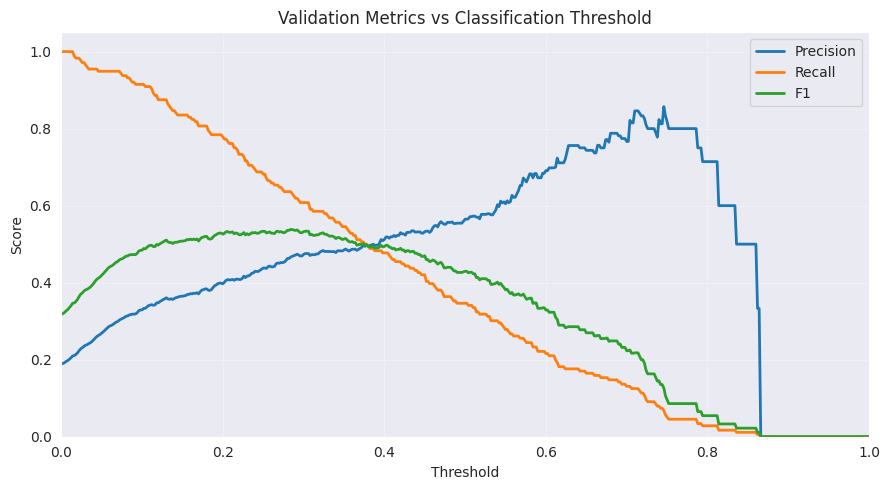

In [ ]:
thresholds = np.linspace(0, 1, 501)

precision_values = []
recall_values = []
f1_values = []

for t in thresholds:
    y_pred_val = (p_val >= t).astype(int)

    precision_values.append(
        metrics.precision_score(y_val, y_pred_val, zero_division=0)
    )
    recall_values.append(
        metrics.recall_score(y_val, y_pred_val, zero_division=0)
    )
    f1_values.append(
        metrics.f1_score(y_val, y_pred_val, zero_division=0)
    )

precision_values = np.array(precision_values)
recall_values = np.array(recall_values)
f1_values = np.array(f1_values)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(thresholds, precision_values, label='Precision', linewidth=2)
ax.plot(thresholds, recall_values, label='Recall', linewidth=2)
ax.plot(thresholds, f1_values, label='F1', linewidth=2)

ax.set(
    xlabel='Threshold',
    ylabel='Score',
    title='Validation Metrics vs Classification Threshold',
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Что мы видим? Precision сначала растёт, достигая максимума где-то `0.85` при `threshold` около `0.75`. После чего точность резко падает. Recall при увеличении `threshold` убывает весьма стремительно, так что при ранее описанном максимальном precision составляет около `0.1`. Такая ситуация и вынуждает смотреть на $F_1$-меру, которая даёт более взвешенную оценку. Её максимум где-то `0.55` достигается при `threshold` около `0.2-0.3`.

In [ ]:
# Все возможные пороги для изменения предсказаний
thresholds_opt = np.unique(np.r_[0.0, p_val, 1.0])

threshold_results = []

for t in thresholds_opt:
    y_pred_val = (p_val >= t).astype(int)

    threshold_results.append({
        'Threshold': t,
        'Precision': metrics.precision_score(
            y_val, y_pred_val, zero_division=0
        ),
        'Recall': metrics.recall_score(
            y_val, y_pred_val, zero_division=0
        ),
        'F1': metrics.f1_score(
            y_val, y_pred_val, zero_division=0
        )
    })

val_results = pd.DataFrame(threshold_results)

# Порог, максимизирующий F1
best_f1_row = val_results.loc[val_results['F1'].idxmax()]
t_f1 = float(best_f1_row['Threshold'])

# Порог, максимизирующий Precision при Recall >= 0.7
valid_thresholds = val_results[
    val_results['Recall'] >= 0.7
]

best_recall_row = valid_thresholds.sort_values(
    ['Precision', 'Threshold'],
    ascending=[False, False]
).iloc[0]

t_r = float(best_recall_row['Threshold'])

# Сводная таблица
optimal_thresholds = pd.DataFrame({
    'Criterion': ['Max F1', 'Max Precision (Recall >= 0.7)'],
    'Threshold': [t_f1, t_r],
    'Precision': [
        best_f1_row['Precision'],
        best_recall_row['Precision']
    ],
    'Recall': [
        best_f1_row['Recall'],
        best_recall_row['Recall']
    ],
    'F1': [
        best_f1_row['F1'],
        best_recall_row['F1']
    ]
})

display(
    optimal_thresholds.style
    .hide(axis='index')
    .format({
        'Threshold': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
    .background_gradient(
        subset=['Precision', 'Recall', 'F1'],
        cmap='Blues'
    )
)

Criterion,Threshold,Precision,Recall,F1
Max F1,0.2865,0.4703,0.6307,0.5388
Max Precision (Recall >= 0.7),0.2364,0.4261,0.7045,0.5310


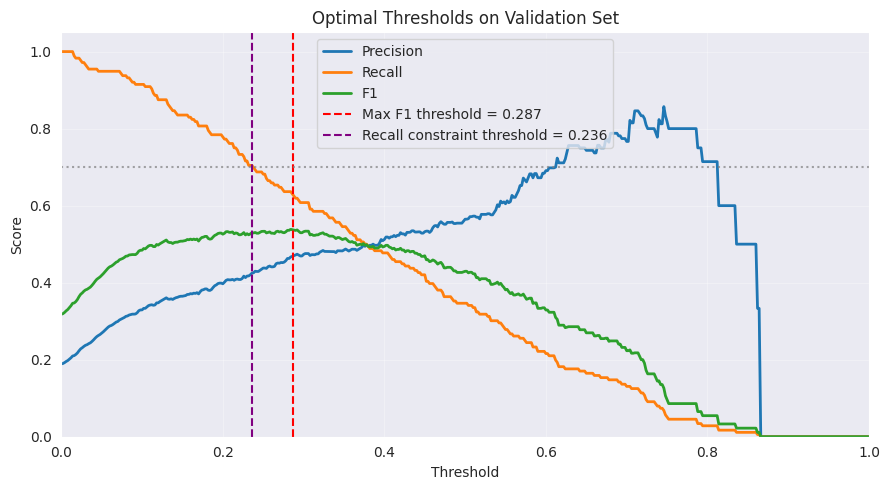

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(thresholds, precision_values, label='Precision', linewidth=2)
ax.plot(thresholds, recall_values, label='Recall', linewidth=2)
ax.plot(thresholds, f1_values, label='F1', linewidth=2)

ax.axvline(
    t_f1,
    color='red',
    linestyle='--',
    label=f'Max F1 threshold = {t_f1:.3f}'
)

ax.axvline(
    t_r,
    color='purple',
    linestyle='--',
    label=f'Recall constraint threshold = {t_r:.3f}'
)

ax.axhline(0.7, color='gray', linestyle=':', alpha=0.7)

ax.set(
    xlabel='Threshold',
    ylabel='Score',
    title='Optimal Thresholds on Validation Set',
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Интересно, что $F_1$-мера по двум критериям мало отличается, хотя есть заметная разница в precision и recall. При максимизации $F_1$-меры мы получаем модель с неплохим recall и не очень хорошим precision. Если чуть поменять порог, пожертвовав ещё precision, то можно получить recall больше `0.7` (на валидации), что и требуется для сервиса.

In [ ]:
# Переобучение на полном train
model_final = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)

model_final.fit(X_train, y_train)

# Вероятности на тесте
p_test = model_final.predict_proba(X_test)[:, 1]

# Сравниваемые пороги
test_thresholds = {
    'Default (0.5)': 0.5,
    'Max F1': t_f1,
    'Recall >= 0.7': t_r
}

test_results = []

for name, t in test_thresholds.items():
    y_pred_test = (p_test >= t).astype(int)

    test_results.append({
        'Threshold type': name,
        'Threshold': t,
        'Precision': metrics.precision_score(
            y_test, y_pred_test, zero_division=0
        ),
        'Recall': metrics.recall_score(
            y_test, y_pred_test, zero_division=0
        ),
        'F1': metrics.f1_score(
            y_test, y_pred_test, zero_division=0
        )
    })

test_results = pd.DataFrame(test_results)

display(
    test_results.style
    .hide(axis='index')
    .format({
        'Threshold': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
    .background_gradient(
        subset=['Precision', 'Recall', 'F1'],
        cmap='Blues'
    )
)

Threshold type,Threshold,Precision,Recall,F1
Default (0.5),0.5000,0.5227,0.3036,0.3841
Max F1,0.2865,0.4574,0.6205,0.5266
Recall >= 0.7,0.2364,0.4213,0.7063,0.5277


В итоге на тесте порог, подобранный с условием на recall, имеет $F_1$-меру немного, но больше, чем порог подобранный для максимизации $F_1$-меры. Правда это скорее случайность, т.к. разница ничтожная, но это как раз показывает, что условия, подбирающиеся на валидации, могут не выполнятся на новых данных. Хотя всё-таки это не совсем честный пример, потому что разница не значима. Тем не менее такие ситуации могут возникать, т.к. распределение данных на train, validation и test могут отличаться. Чем сильнее разница, тем больше шансы на это.

Судя по условию задачи, предполагалось, что на тесте recall не будет больше `0.7`. Я перезапустил ячейки и увидел, что у меня такой проблемы не возникло, как раз из-за полного удаления дубликатов. В итоге моя предостороженность оправдалась, и порог, подобранный для условия максимизации $F_1$-меры при условии recall не меньше `0.7`, даже даёт лучшую $F_1$-меру из рассмотренных. Учитывая описание сценария "Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной)", этот порог, равный `0.2364`, самый оптимальный именно из-за выполнения условия на recall и относительно большой $F_1$-меры, что означает достаточно большой precision.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

In [ ]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Accuracy': metrics.accuracy_score(y_test, y_pred),
        'Precision': metrics.precision_score(y_test, y_pred, zero_division=0),
        'Recall': metrics.recall_score(y_test, y_pred, zero_division=0),
        'F1': metrics.f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_test, y_proba),
        'PR-AUC': metrics.average_precision_score(y_test, y_proba)
    }


def display_results(results):
    df_results = pd.DataFrame(results)

    return (
        df_results.style
        .hide(axis='index')
        .format({
            col: '{:.4f}'
            for col in df_results.columns
            if col != 'Model'
        })
        .background_gradient(
            subset=['Accuracy', 'Precision', 'Recall', 'F1',
                    'ROC-AUC', 'PR-AUC'],
            cmap='Blues'
        )
    )

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [ ]:
# Численность классов в тренировочной выборке
class_counts = y_train.value_counts().sort_index()

n_samples = len(y_train)
n_classes = y_train.nunique()

class_weights = n_samples / (n_classes * class_counts)

weights_table = pd.DataFrame({
    'Class': class_counts.index,
    'Count': class_counts.values,
    'Weight': class_weights.values
})

display(
    weights_table.style
    .hide(axis='index')
    .format({'Weight': '{:.4f}'})
)

Class,Count,Weight
0,3018,0.6170
1,706,2.6374


Веса классов вычислены по формуле из документации sklearn:
$$
w_c = \frac{N}{K \cdot N_c},
$$
где \(N\) — число объектов в обучающей выборке, \(K\) — число классов, \(N_c\) — число объектов класса \(c\).

In [ ]:
# Логистическая регрессия без весов
model_unweighted = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight=None,
        max_iter=1000,
        random_state=RANDOM_STATE
    )
)

# Логистическая регрессия с балансировкой весов
model_weighted = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=RANDOM_STATE
    )
)

model_unweighted.fit(X_train, y_train)
model_weighted.fit(X_train, y_train)

# Оценка на одной и той же тестовой выборке
result_unweighted = evaluate_model(
    model_unweighted, X_test, y_test, 'Without weights'
)

result_weighted = evaluate_model(
    model_weighted, X_test, y_test, 'Balanced weights'
)

# Итоговая таблица
results_31 = [result_unweighted, result_weighted]

display(display_results(results_31))

Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Without weights,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
Balanced weights,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811


*Ваши выводы здесь.*

Про веса классов особо сказать ничего, кроме того, что они существенно отличаются, а вот про метрики можно сказать больше.
- Accuracy упал для модели со сбалансированными классами, но классы несбалансированы, поэтому это не имеет значения.
- Precision и Recall изменились. Первый стал меньше, второй сильно больше, но в целом $F_1$-мера значительно выросал. Причём это уровень лучших результатов, полученных в прошлой части дз. Разница в том, что там мы подбирали порог, а здесь фактически только изменили функцию потерь. Классный результат для столь простого изменения.
- ROC-AUC и PR-AUC не изменились. Это означает, что качество ранжирование не поменялась. В совокупности с предыдущим пунктом это показывает, что в данном случае добавление весов заменило подбор оптимального порога, который сейчас видимо как раз равен `0.5` или около того.

Сказать деталь почему так происходит сложно, но в целом это влияние изменения функции потерь. При этом ещё раз отмечу, что балансировка весов не обязательно улучшает способность модели отличать хорошие вина от плохих в смысле ранжирования.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [ ]:
samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss (v2)': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE)
}

models_sampling = {}

for name, sampler in samplers.items():
    model = make_pipeline(
        StandardScaler(),
        sampler,
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )

    model.fit(X_train, y_train)
    models_sampling[name] = model

In [ ]:
# Исходное распределение классов
original_counts = y_train.value_counts()

sampling_results = [{
    'Method': 'Original (no sampling)',
    'Class 0': original_counts.get(0, 0),
    'Class 1': original_counts.get(1, 0),
    'Total': len(y_train)
}]

# Распределение классов после ресемплинга
for name, model in models_sampling.items():
    scaler = model.steps[0][1]
    sampler = model.steps[1][1]

    X_train_scaled = scaler.transform(X_train)
    X_resampled, y_resampled = sampler.fit_resample(
        X_train_scaled, y_train
    )

    counts = pd.Series(y_resampled).value_counts()

    sampling_results.append({
        'Method': name,
        'Class 0': counts.get(0, 0),
        'Class 1': counts.get(1, 0),
        'Total': len(y_resampled)
    })

sampling_table = pd.DataFrame(sampling_results)

display(
    sampling_table.style
    .hide(axis='index')
    .format({
        'Class 0': '{:,}',
        'Class 1': '{:,}',
        'Total': '{:,}'
    })
    .background_gradient(
        subset=['Class 0', 'Class 1', 'Total'],
        cmap='Blues'
    )
)

Method,Class 0,Class 1,Total
Original (no sampling),"3,018",706,"3,724"
RandomUnderSampler,706,706,"1,412"
NearMiss (v2),706,706,"1,412"
RandomOverSampler,"3,018","3,018","6,036"
SMOTE,"3,018","3,018","6,036"


По этой табличке видно, что представленые методы делятся на 2 типа:
- Undersampling методы: `RandomUnderSampler` и `NearMiss (v2)`. С этими методами размера train стал совсем маленьким. Без удаления дублей в train было `4547` объектов, после удаления `3724`, а с учётом этих методов вообще `1412`, то есть более чем в 3 раза меньше. Можно ожидать, что с этими методами качество будет хуже или по крайней мере не измениться.
- Oversampling методы: `RandomOverSampler` и `SMOTE`. Они увеличивают размер текущего train в 1.6 раз, так что это полностью покрывает уменьшение данных из-за удаления дублей. С этими методами хочется ожидать повышение или неухудшения качества.

In [ ]:
# Результаты моделей с ресемплингом
results_sampling = [
    evaluate_model(model, X_test, y_test, name)
    for name, model in models_sampling.items()
]

# Объединение с результатами задания 3.1
results_32 = results_31 + results_sampling

display(display_results(results_32))

Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Without weights,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
Balanced weights,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
RandomUnderSampler,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss (v2),0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796


Пройдёмся по каждому методу балансировки классов:
- `RandomUnderSample`. Несмотря на значительное уменьшение объёма train, качество по всем метрикам идентично методу со сбалансированными весами. В целом оно логично, так как суммарный вклад положительного и отрицательного классов с одинаковыми размерами в функцию потерь одинаков, поэтому для модели эти ситуации выглядят похоже. Другое дело, что данных стало в 2.6 раза меньше, а модель этого не почувствовала. Причина кроется в использованном методе, который удаляет случайные объекты большого по размеру класса. Получается, что удаление равномерное, что для данной задачи допустимо, поэтому качество не меняется.
- `NearMiss (v2)`. Этот метод также уменьшил объём train, но качество немного, но просело, причём почти по всем метрикам. Собственно говоря, он работает иначе. Метод отбирает объекты на основании расстояний до меньшего класса. Точные причины непонятны, но решаемая задача такова, что такой подход в купе с логичестической регрессией даёт качество похуже. Разве что Recall самый большой среди описанных в табличке.
- `RandomOverSampler`. Ситуация аналогична методу `RandomUnderSample` с той разницей, что размер train стал больше, а не меньше. Здесь также влияние этого метода состоит в том, что вклад в функцию потерь положительного и отрицательного классов стал одинаков, поэтому качество идентично методу с балансировкой весов. Интересно, что этот метод в сущности гораздо сильнее похож на `Balanced weights`, так как тут случайные объекты меньшего класса дублируются, что даёт им больший вклад в функцию потерь, как это происходит при балансировки весов классов.
- `SMOTE`. Не буду притягивать крошечное различие в Recall за разницу и скажу, что тут тоже самое, что с методом `RandomOverSampler`, то есть качество и механизм изменения как у метода с балансировкой весов. `SMOTE` создаёт новые объекты как случайную линейную комбинацию близко лежащих объектов. Это даёт равномерное распределение новых объектов, а также в целом похоже на обратный процесс к `RandomUnderSample`.

Итого, методы `RandomUnderSample`, `RandomOverSampler`, `SMOTE` дают качество аналогичное методу `Balanced weights`, причём механизм достижение результата также схож.

*Ваши выводы здесь.* Ответы на вопросы:
- `make_pipeline` из `imblearn` необходим, поскольку он поддерживает ресемплеры (`RandomUnderSampler`, `SMOTE` и другие), которые используют метод `fit_resample`. Обычный `sklearn.pipeline.make_pipeline` не поддерживает такие промежуточные этапы. Замечу, что класс `Transformer` из `sklearn` не подходит для ресемплинга, поскольку интерфейс `transform` не позволяет корректно передать изменённую целевую переменную следующему этапу пайплайна, он изменяет только признаки.
- Если мы будем балансировать весь датасет, а потом разбивать его на train и test, то у нас почти наверное будут проблемы. При oversampling в test могут попасть дубликаты объектов или сгенерированные объекты (зависит от метода), что является прямым data leakage. Но в целом при undersampling и oversampling проблема в том, что мы меняем распределение данных. До балансировки у нас есть разница в размерах, которая очевидно присутствует и в реальных данных. Если мы сбалансируем датасет, то в test будет такое же неправильное распределение как в train, поэтому оценка качества будет неадекватной.
- В целом все методы, кроме `NearMiss (v2)` показали идентичное качество по PR-AUC. Выше я уже отмечал, что вероятная причина в природе данных, для которых такое удаление объектов нехарактерно. Также выше я говорил, что в сущности методы `Balanced weights`, `RandomUnderSample`, `RandomOverSampler` и `SMOTE` работают одинаково. При этом разницы с `Without weights` нет, что означает отсутствие разницы в качестве ранжирования, даже с учётом дисбаланса классов. В целом все методы хороши)
- Далее интересный вопрос о важностьи порядка шагов «ресемплинг» и «масштабирование» в пайплайне для некоторых методов. Всё, конечно, зависит от их устройства, поэтому методы `RandomUnderSample` и `RandomOverSampler`, которые не смотрят на признаки объектов, а просто их удаляют или дублируют не зависят от порядка этих шагов. В тоже время методы `NearMiss (v2)` и `SMOTE` смотрят на расстояние между объектами, которое меняется при масштабирование, поэтому для них порядок шагов «ресемплинг» и «масштабирование» в пайплайне важен. Не буду мелочиться и проверю для всех методов, что будет, если изменить порядок шагов.

In [ ]:
samplers_reversed = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss (v2)': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE)
}

models_sampling_reversed = {}

for name, sampler in samplers_reversed.items():
    model = make_pipeline(
        sampler,
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )

    model.fit(X_train, y_train)
    models_sampling_reversed[name] = model


# Результаты экспериментальных моделей
results_sampling_reversed = [
    evaluate_model(model, X_test, y_test, name)
    for name, model in models_sampling_reversed.items()
]

# Исходные модели из 3.1
results_baseline = [
    {**result, 'Pipeline': 'Scaler → LR'}
    for result in results_31
]

# Исходные методы: Scaler → Sampler → LR
results_original = [
    {**result, 'Pipeline': 'Scaler → Sampler → LR'}
    for result in results_sampling
]

# Экспериментальные методы: Sampler → Scaler → LR
results_reversed = [
    {**result, 'Pipeline': 'Sampler → Scaler → LR'}
    for result in results_sampling_reversed
]

# Общая таблица
results_comparison = pd.DataFrame(
    results_baseline + results_original + results_reversed
)

# Порядок столбцов
results_comparison = results_comparison[
    [
        'Model', 'Pipeline', 'Accuracy',
        'Precision', 'Recall', 'F1',
        'ROC-AUC', 'PR-AUC'
    ]
]

display(
    results_comparison.style
    .hide(axis='index')
    .format({
        col: '{:.4f}'
        for col in [
            'Accuracy', 'Precision', 'Recall', 'F1',
            'ROC-AUC', 'PR-AUC'
        ]
    })
    .background_gradient(
        subset=[
            'Accuracy', 'Precision', 'Recall', 'F1',
            'ROC-AUC', 'PR-AUC'
        ],
        cmap='Blues'
    )
)

Model,Pipeline,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Without weights,Scaler → LR,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
Balanced weights,Scaler → LR,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
RandomUnderSampler,Scaler → Sampler → LR,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss (v2),Scaler → Sampler → LR,0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,Scaler → Sampler → LR,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,Scaler → Sampler → LR,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796
RandomUnderSampler,Sampler → Scaler → LR,0.7337,0.3966,0.7723,0.5241,0.8206,0.4799
NearMiss (v2),Sampler → Scaler → LR,0.6303,0.3063,0.7492,0.4349,0.7423,0.3581
RandomOverSampler,Sampler → Scaler → LR,0.7337,0.3990,0.7954,0.5314,0.8211,0.4810
SMOTE,Sampler → Scaler → LR,0.7393,0.4024,0.7690,0.5283,0.8216,0.4852


Кажется, данных стало слишком много или расположение и текстовое выделение строк не слишком удачное. Тем не менее можно увидеть, что результаты для `RandomUnderSampler` и `RandomOverSampler` не изменились. Результаты `NearMiss (v2)` стали хуже, а вот для `SMOTE` к моему удивлению порядок не сыграли роли, и кроме того всё сложилось так, что модель с этим методом получила лучшие результаты в табличке. Почему так случилось? Потому что датасет такой.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

In [ ]:
# Вероятности положительного класса
p_weighted = model_weighted.predict_proba(X_test)[:, 1]
p_unweighted = model_unweighted.predict_proba(X_test)[:, 1]

# Пороги классификации
t_weighted = 0.5
t_unweighted = t_f1

# Предсказания классов
y_pred_weighted = (p_weighted >= t_weighted).astype(int)
y_pred_unweighted = (p_unweighted >= t_unweighted).astype(int)

# Сравнение метрик
results_33 = pd.DataFrame([
    {
        'Model': 'Balanced weights',
        'Threshold': t_weighted,
        'Precision': metrics.precision_score(y_test, y_pred_weighted),
        'Recall': metrics.recall_score(y_test, y_pred_weighted),
        'F1': metrics.f1_score(y_test, y_pred_weighted)
    },
    {
        'Model': 'Without weights',
        'Threshold': t_unweighted,
        'Precision': metrics.precision_score(y_test, y_pred_unweighted),
        'Recall': metrics.recall_score(y_test, y_pred_unweighted),
        'F1': metrics.f1_score(y_test, y_pred_unweighted)
    }
])

display(
    results_33.style
    .hide(axis='index')
    .format({
        'Threshold': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    })
    .background_gradient(
        subset=['Precision', 'Recall', 'F1'],
        cmap='Blues'
    )
)

Model,Threshold,Precision,Recall,F1
Balanced weights,0.5000,0.3987,0.7855,0.5289
Without weights,0.2865,0.4574,0.6205,0.5266


С точки зрения $F_1$-меры разницы нет, но Precision и Recall отличаются, поэтому выбор зависит от конкретных требований.

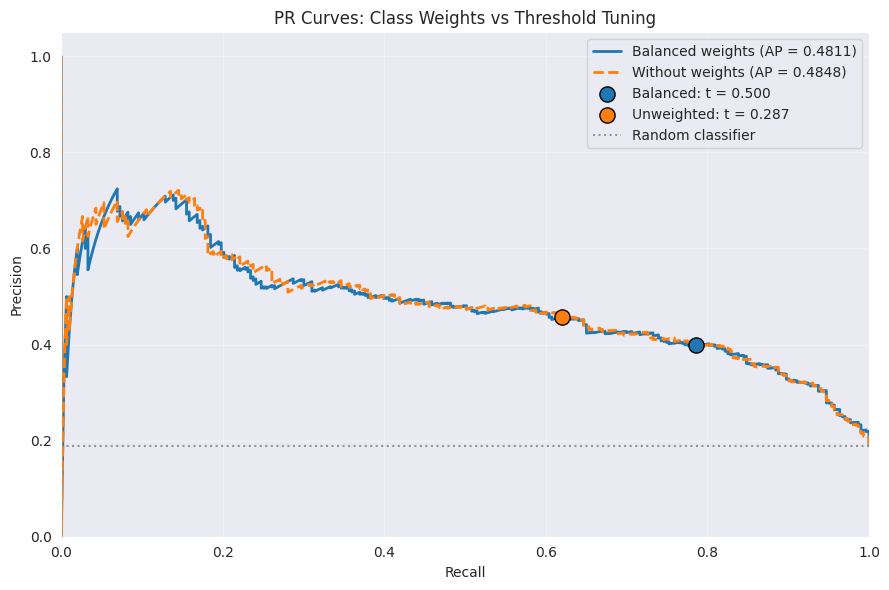

In [ ]:
# PR-кривые
precision_w, recall_w, _ = metrics.precision_recall_curve(
    y_test, p_weighted
)
precision_u, recall_u, _ = metrics.precision_recall_curve(
    y_test, p_unweighted
)

# Значения метрик при выбранных порогах
point_w = (
    results_33.loc[0, 'Recall'],
    results_33.loc[0, 'Precision']
)

point_u = (
    results_33.loc[1, 'Recall'],
    results_33.loc[1, 'Precision']
)

# PR-AUC
ap_weighted = metrics.average_precision_score(y_test, p_weighted)
ap_unweighted = metrics.average_precision_score(y_test, p_unweighted)

# Визуализация
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    recall_w, precision_w,
    linewidth=2,
    label=f'Balanced weights (AP = {ap_weighted:.4f})'
)

ax.plot(
    recall_u, precision_u,
    linewidth=2,
    linestyle='--',
    label=f'Without weights (AP = {ap_unweighted:.4f})'
)

# Выделяем выбранные пороги
ax.scatter(
    *point_w,
    s=120,
    color='tab:blue',
    edgecolor='black',
    linewidth=1,
    zorder=5,
    label=f'Balanced: t = {t_weighted:.3f}'
)

ax.scatter(
    *point_u,
    s=120,
    color='tab:orange',
    edgecolor='black',
    linewidth=1,
    zorder=5,
    label=f'Unweighted: t = {t_unweighted:.3f}'
)

# Уровень случайного классификатора
ax.axhline(
    y_test.mean(),
    color='gray',
    linestyle=':',
    alpha=0.8,
    label='Random classifier'
)

ax.set(
    xlabel='Recall',
    ylabel='Precision',
    title='PR Curves: Class Weights vs Threshold Tuning',
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

PR-кривые слегка отличаются, но в целом они почти одинаковые, особенно в части PR-AUC как мы видели ранее. При этом, как я уже отметил, $F_1$-мера одинаковая, а Precision и Recall разные, а также пороги у моделей разные. Всё это в купе действительно позволяет говорить, что взвешивание классов в основном "сдвигает порог", так как ранжирование объектов почти не изменилось. По сути мы можем изменить порог одной модели и получить ответы и метрики как у другой. В чём же тогда смысл применения взвешивания классов? Для того чтобы подобрать порог, максимизирующий $F_1$-меру, использовалась отдельная валидационная выборка и перебор разных порогов. Модель со взвешиванием была просто обучена и использует станадартный порог `0.5`, получая при этом качество анологично предыдущей. Таким образом взвешивание классов избавляет нас от необходимости перебирать оптимальный порог для получения модели, максимизирующей $F_1$-меру. Это позволяет сэкономить вычислительные ресурсы, особенно для моделей с более тяжелым inference. Более того, эту идею можно расширить, задавая веса классов на основе требований задачи и контролируя важность классов вручную. С этой точки зрения вместо обучения кучи моделей с разными весами классов гораздо проще всё же перебрать пороги. С другой стороны в многоклассовой классификации использование порога сложнее, поэтому может быть такой способ проще в реализации.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [ ]:
# Модели с порогом по умолчанию (0.5)
models_default = {
    'Dummy (constant 0)': model_dummy,
    'LogReg (sklearn)': model_unweighted,
    'LogReg (Custom GD)': model_custom,
    'LogReg (balanced)': model_weighted,
    **models_sampling
}

# Универсальная оценка с произвольным порогом
def evaluate_with_threshold(model, X_test, y_test, name, threshold=0.5):
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    return {
        'Model': name,
        'Threshold': threshold,
        'Accuracy': metrics.accuracy_score(y_test, y_pred),
        'Precision': metrics.precision_score(y_test, y_pred, zero_division=0),
        'Recall': metrics.recall_score(y_test, y_pred, zero_division=0),
        'F1': metrics.f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_test, y_proba),
        'PR-AUC': metrics.average_precision_score(y_test, y_proba)
    }

# Оценка всех моделей
results_34 = [
    evaluate_with_threshold(model, X_test, y_test, name)
    for name, model in models_default.items()
]

# Модели с порогами из задания 2.5
results_34.extend([
    evaluate_with_threshold(
        model_final, X_test, y_test,
        'LogReg (max F1 threshold)', t_f1
    ),
    evaluate_with_threshold(
        model_final, X_test, y_test,
        'LogReg (recall >= 0.7)', t_r
    )
])

# Итоговая таблица
results_34 = pd.DataFrame(results_34)

display(
    results_34.style
    .hide(axis='index')
    .format({
        col: '{:.4f}'
        for col in results_34.columns
        if col != 'Model'
    })
    .background_gradient(
        subset=[
            'Accuracy', 'Precision', 'Recall',
            'F1', 'ROC-AUC', 'PR-AUC'
        ],
        cmap='Blues'
    )
)

Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy (constant 0),0.5000,0.8102,0.0000,0.0000,0.0000,0.5000,0.1898
LogReg (sklearn),0.5000,0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
LogReg (Custom GD),0.5000,0.8145,0.5200,0.3003,0.3808,0.8206,0.4838
LogReg (balanced),0.5000,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
RandomUnderSampler,0.5000,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss (v2),0.5000,0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,0.5000,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,0.5000,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796
LogReg (max F1 threshold),0.2865,0.7882,0.4574,0.6205,0.5266,0.8209,0.4848
LogReg (recall >= 0.7),0.2364,0.7600,0.4213,0.7063,0.5277,0.8209,0.4848


Моделей много, поэтому сначала вспомним, что по условию "Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной)". Значит, во-первых, мы хотим модель с наибольшей $F_1$-мерой. Таких кандидатов много: `LogReg (balanced)`, `RandomUnderSampler`, `RandomOverSampler`, `SMOTE`, `LogReg (max F1 threshold)`, `LogReg (recall >= 0.7)`. У них также одинаковые ROC-AUC и PR-AUC, а из-за дисбаланса классов Accuracy учитывать смысла нет, поэтому нужно смотреть на конкретные значения Precision и Recall. Так как среди описанных моделей почти у всех почти все метрики совпадают, то я бы выделил `RandomOverSampler`, имеющий наибольший Recall, то есть покрывающий наиболее число хороших вин. Эту модель я и предложил бы использовать. Остановимся на ней.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [ ]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

# Итоговая модель и порог
final_model = models_sampling['RandomOverSampler']
final_threshold = 0.5

# Сохранение пайплайна
joblib.dump(final_model, app_dir / 'model.joblib')

# Сохранение порога
(app_dir / 'config.json').write_text(
    json.dumps({'threshold': float(final_threshold)}),
    encoding='utf-8'
)

# Сохранение тестовой выборки
X_test.assign(target=y_test).to_csv(
    app_dir / 'test.csv',
    index=False
)

print(f'Model saved to: {app_dir.resolve()}')

Model saved to: /content/wine_app


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷